In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [4]:
device = torch.device("mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:01<00:00, 6.28MB/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 356kB/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:00<00:00, 1.90MB/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<00:00, 6.11MB/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



In [5]:
image, label = train_dataset[0]
print(image.shape, image.dtype, image.min().item(), image.max().item(), label)

torch.Size([1, 28, 28]) torch.float32 0.0 1.0 5


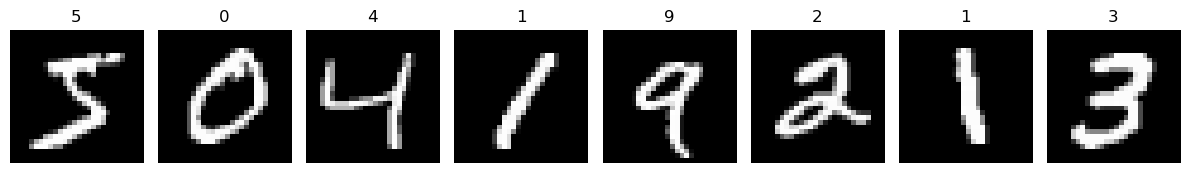

In [6]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for i in range(8):
    img, lbl = train_dataset[i]
    axes[i].imshow(img.squeeze(), cmap="gray")
    axes[i].set_title(lbl)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [7]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [8]:
class NeuralNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = NeuralNet().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [9]:
epochs = 3

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    bar = tqdm(train_loader, desc=f"{epoch + 1}/{epochs}")
    for i, (images, labels) in enumerate(bar, 1):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        bar.set_postfix(loss=f"{running_loss / i:.4f}")

1/3:   0%|          | 0/938 [00:00<?, ?it/s]

2/3:   0%|          | 0/938 [00:00<?, ?it/s]

3/3:   0%|          | 0/938 [00:00<?, ?it/s]

In [10]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        predicted = model(images).argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(100 * correct / total)

97.16


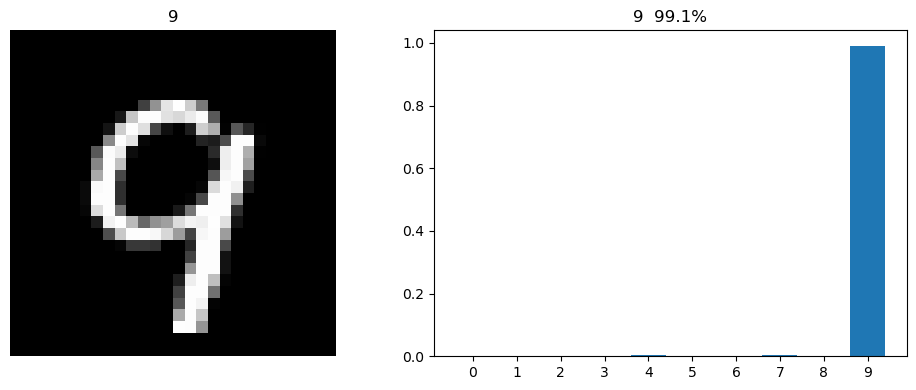

In [17]:
idx = 16

image, label = test_dataset[idx]

with torch.no_grad():
    probs = F.softmax(model(image.unsqueeze(0).to(device)), dim=1).cpu().squeeze()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.imshow(image.squeeze(), cmap="gray")
ax1.set_title(label)
ax1.axis("off")

ax2.bar(range(10), probs.numpy())
ax2.set_xticks(range(10))
ax2.set_title(f"{probs.argmax().item()}  {100 * probs.max().item():.1f}%")

plt.tight_layout()
plt.show()